In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

SEED = 42

PROJECT_ROOT = Path(r"C:\Case Study Trees\AdultCensusStudy")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"

sns.set_theme(style="whitegrid")

print("Files in the raw folder:")

for file in RAW_DIR.iterdir():
    if file.is_file():
        print(file.name)

Files in the raw folder:
adult.csv


In [2]:
df = pd.read_csv(RAW_DIR / "adult.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Rows: 32561
Columns: 15

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [3]:
text_columns = df.select_dtypes(include="object").columns

for column in text_columns:
    df[column] = df[column].str.strip()

print("Income labels:")
print(df["income"].value_counts(dropna=False))

missing_summary = pd.DataFrame({
    "Missing_NaN": df.isna().sum(),
    "Question_Marks": df.eq("?").sum()
})

display(
    missing_summary[
        missing_summary.sum(axis=1) > 0
    ]
)

Income labels:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64


,Missing_NaN,Question_Marks
workclass,0,1836
occupation,0,1843
native.country,0,583


In [4]:
df = df.replace("?", np.nan)
df["income"] = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

assert df["income"].notna().all()

print("Encoded target:")
print(df["income"].value_counts().sort_index())

print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])

Encoded target:
income
0    24720
1     7841
Name: count, dtype: int64

Missing values:
workclass         1836
occupation        1843
native.country     583
dtype: int64


In [5]:
duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(10))

Exact duplicate rows: 24


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
6227,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,0
7615,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,0
7978,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,0
8356,21,Private,250051,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,10,United-States,0
8453,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,0
8500,38,Private,207202,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,48,United-States,1
8645,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,0
9067,27,Private,255582,HS-grad,9,Never-married,Machine-op-inspct,Not-in-family,White,Female,0,0,40,United-States,0
9269,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,0
9305,25,Private,195994,1st-4th,2,Never-married,Priv-house-serv,Not-in-family,White,Female,0,0,40,Guatemala,0


In [6]:
df = df.drop_duplicates().reset_index(drop=True)

print("Rows after removing duplicates:", len(df))
print("Remaining duplicates:", df.duplicated().sum())

Rows after removing duplicates: 32537
Remaining duplicates: 0


In [7]:
train_valid_df, test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=SEED,
    stratify=df["income"]
)

train_df, valid_df = train_test_split(
    train_valid_df,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_valid_df["income"]
)

for name, data in [
    ("Training", train_df),
    ("Validation", valid_df),
    ("Test", test_df)
]:
    print(
        name,
        "| Rows:", len(data),
        "| Income >50K:", round(data["income"].mean() * 100, 2), "%"
    )

Training | Rows: 22775 | Income >50K: 24.09 %
Validation | Rows: 4881 | Income >50K: 24.09 %
Test | Rows: 4881 | Income >50K: 24.09 %


In [8]:
assert set(train_df.index).isdisjoint(valid_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(valid_df.index).isdisjoint(test_df.index)

assert len(train_df) + len(valid_df) + len(test_df) == len(df)

SPLIT_DIR.mkdir(parents=True, exist_ok=True)

for name, data in [
    ("train", train_df),
    ("valid", valid_df),
    ("test", test_df)
]:
    
    saved_data = data.rename_axis("ROW_ID").reset_index()

    saved_data.to_csv(SPLIT_DIR / f"{name}.csv", index=False)

    print("Saved:", f"{name}.csv", saved_data.shape)

Saved: train.csv (22775, 16)
Saved: valid.csv (4881, 16)
Saved: test.csv (4881, 16)


,Applicants,Percentage
Income <=50K,17288,75.91
Income >50K,5487,24.09


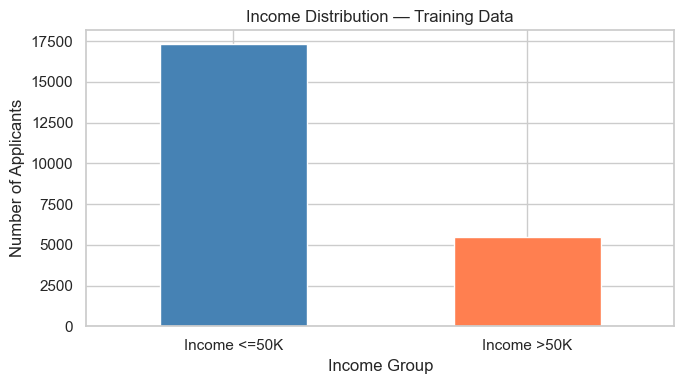

In [9]:
eda_df = train_df.copy()

income_counts = eda_df["income"].value_counts().sort_index()

income_summary = pd.DataFrame({
    "Applicants": income_counts,
    "Percentage": (income_counts / len(eda_df) * 100).round(2)
})

income_summary.index = ["Income <=50K", "Income >50K"]

display(income_summary)

income_summary["Applicants"].plot.bar(
    figsize=(7, 4),
    color=["steelblue", "coral"],
    rot=0
)

plt.title("Income Distribution — Training Data")
plt.xlabel("Income Group")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

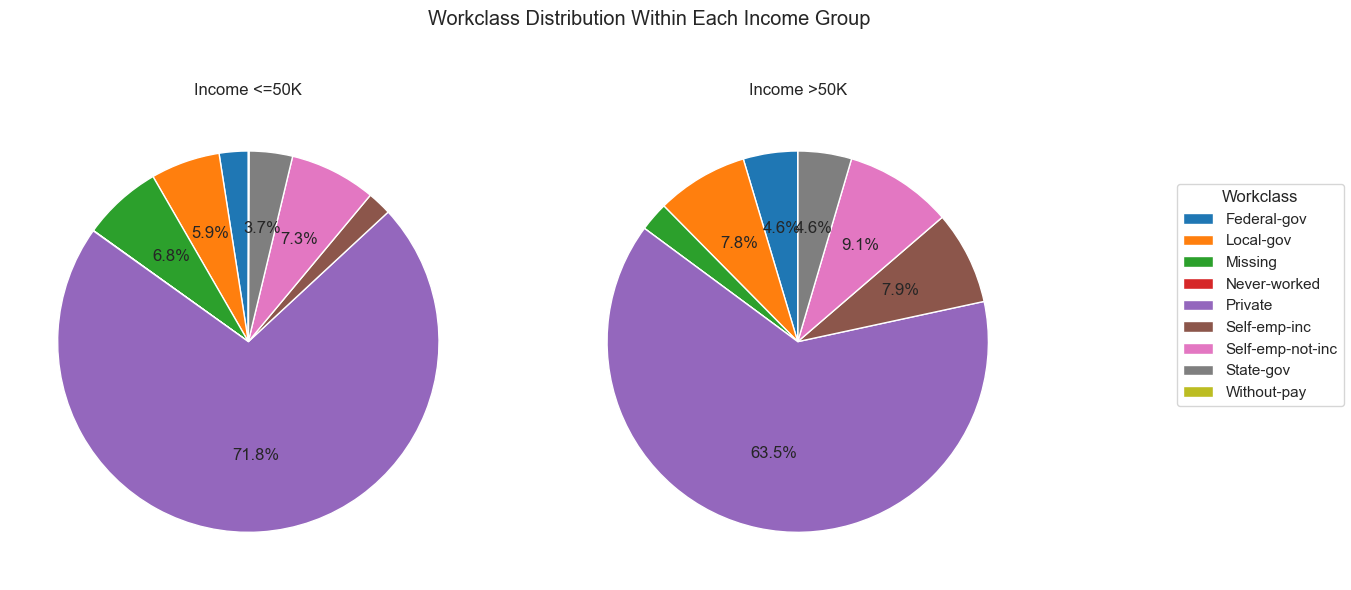

In [10]:
workclass_counts = pd.crosstab(
    eda_df["workclass"].fillna("Missing"),
    eda_df["income"]
)

colors = sns.color_palette("tab10", n_colors=len(workclass_counts))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, income_value, title in [
    (axes[0], 0, "Income <=50K"),
    (axes[1], 1, "Income >50K")
]:
    wedges, _, _ = ax.pie(
        workclass_counts[income_value],
        colors=colors,
        autopct=lambda percentage: (
            f"{percentage:.1f}%" if percentage >= 3 else ""
        ),
        startangle=90
    )

    ax.set_title(title)

fig.legend(
    wedges,
    workclass_counts.index,
    title="Workclass",
    loc="center right"
)

plt.suptitle("Workclass Distribution Within Each Income Group")
plt.tight_layout(rect=[0, 0, 0.82, 0.95])
plt.show()

,Applicants,Above_50K_Percentage
workclass,,
Never-worked,5,0.00
Without-pay,10,0.00
Missing,1305,10.42
Private,15893,21.93
State-gov,886,28.22
Self-emp-not-inc,1766,28.37
Local-gov,1443,29.59
Federal-gov,678,37.32
Self-emp-inc,789,55.13


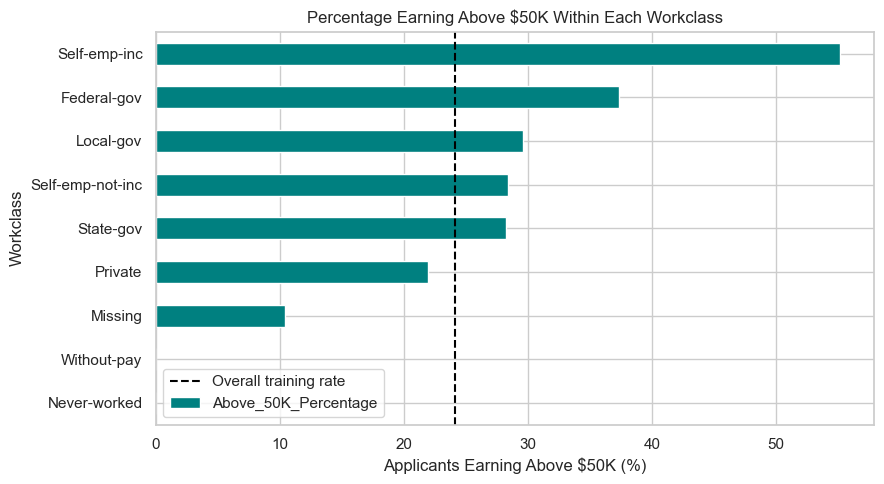

In [11]:
workclass_summary = (
    eda_df.groupby(eda_df["workclass"].fillna("Missing"))["income"]
    .agg(["size", "mean"])
)

workclass_summary.columns = ["Applicants", "Above_50K_Percentage"]

workclass_summary["Above_50K_Percentage"] *= 100

workclass_summary = workclass_summary.sort_values(
    "Above_50K_Percentage"
)

display(workclass_summary.round(2))

workclass_summary["Above_50K_Percentage"].plot.barh(
    figsize=(9, 5),
    color="teal"
)

plt.axvline(
    eda_df["income"].mean() * 100,
    color="black",
    linestyle="--",
    label="Overall training rate"
)

plt.title("Percentage Earning Above $50K Within Each Workclass")
plt.xlabel("Applicants Earning Above $50K (%)")
plt.ylabel("Workclass")
plt.legend()
plt.tight_layout()
plt.show()

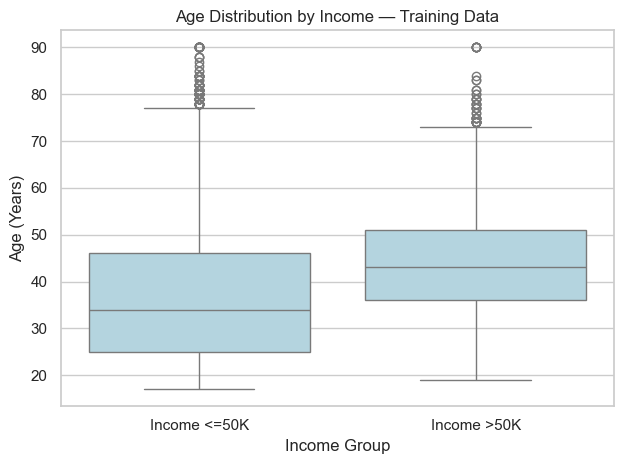

,count,median,mean
income,,,
0,17288,34.0,36.76
1,5487,43.0,44.19


In [12]:
sns.boxplot(
    data=eda_df,
    x="income",
    y="age",
    order=[0, 1],
    color="lightblue"
)

plt.xticks([0, 1], ["Income <=50K", "Income >50K"])
plt.title("Age Distribution by Income — Training Data")
plt.xlabel("Income Group")
plt.ylabel("Age (Years)")
plt.tight_layout()
plt.show()

display(
    eda_df.groupby("income")["age"]
    .agg(["count", "median", "mean"])
    .round(2)
)

,Applicants,Above_50K_Percentage
education,,
Preschool,36,0.00
1st-4th,114,4.39
5th-6th,239,5.02
7th-8th,453,5.30
9th,364,6.04
10th,653,6.13
11th,813,5.29
12th,307,7.49
HS-grad,7335,15.91


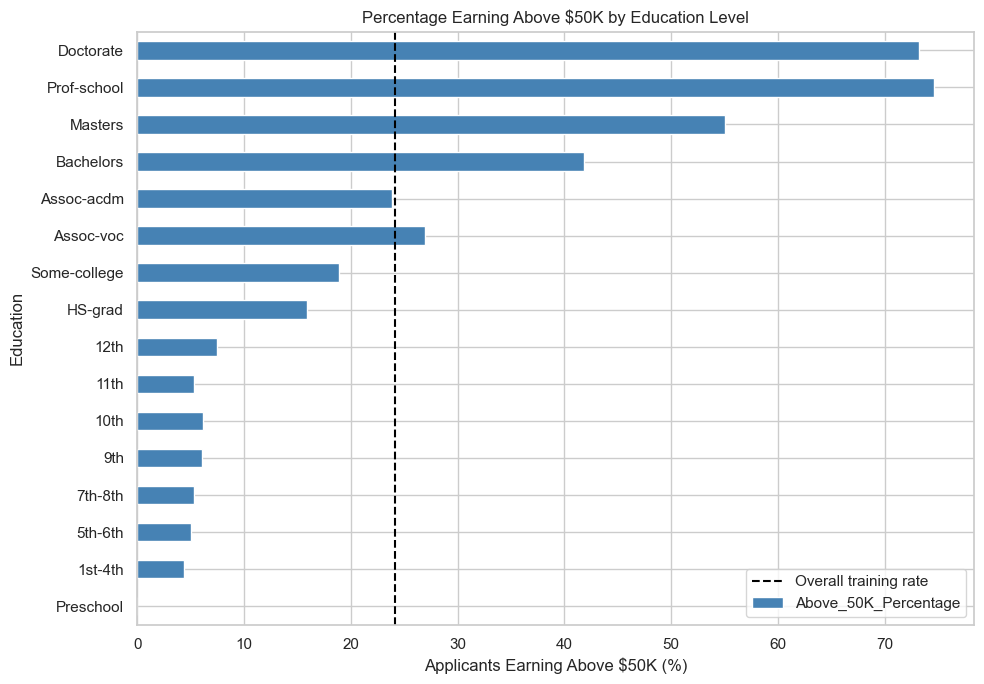

In [13]:
education_order = (
    eda_df[["education", "education.num"]]
    .drop_duplicates()
    .sort_values("education.num")["education"]
    .tolist()
)

education_summary = (
    eda_df.groupby("education")["income"]
    .agg(["size", "mean"])
    .reindex(education_order)
)

education_summary.columns = ["Applicants", "Above_50K_Percentage"]
education_summary["Above_50K_Percentage"] *= 100

display(education_summary.round(2))

education_summary["Above_50K_Percentage"].plot.barh(
    figsize=(10, 7),
    color="steelblue"
)

plt.axvline(
    eda_df["income"].mean() * 100,
    color="black",
    linestyle="--",
    label="Overall training rate"
)

plt.title("Percentage Earning Above $50K by Education Level")
plt.xlabel("Applicants Earning Above $50K (%)")
plt.ylabel("Education")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
education_mapping = (
    eda_df[["education", "education.num"]]
    .drop_duplicates()
    .sort_values("education.num")
)

display(education_mapping)

assert education_mapping["education"].is_unique
assert education_mapping["education.num"].is_unique

,education,education.num
26083,Preschool,1
13169,1st-4th,2
19322,5th-6th,3
14990,7th-8th,4
25990,9th,5
8878,10th,6
12861,11th,7
4079,12th,8
11727,HS-grad,9
2830,Some-college,10


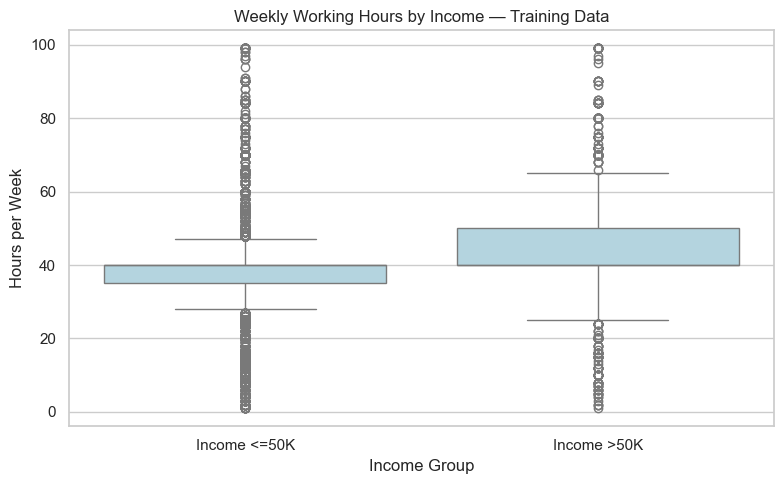

,count,median,mean
income,,,
0,17288,40.0,38.81
1,5487,40.0,45.47


In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="income",
    y="hours.per.week",
    order=[0, 1],
    color="lightblue"
)

plt.xticks([0, 1], ["Income <=50K", "Income >50K"])
plt.title("Weekly Working Hours by Income — Training Data")
plt.xlabel("Income Group")
plt.ylabel("Hours per Week")
plt.tight_layout()
plt.show()

display(
    eda_df.groupby("income")["hours.per.week"]
    .agg(["count", "median", "mean"])
    .round(2)
)

,Applicants,Above_50K_Percentage
occupation,,
Priv-house-serv,105,0.00
Other-service,2291,4.02
Handlers-cleaners,969,6.40
Missing,1310,10.38
Farming-fishing,688,11.34
Machine-op-inspct,1385,12.42
Adm-clerical,2649,13.51
Armed-Forces,6,16.67
Transport-moving,1089,19.10


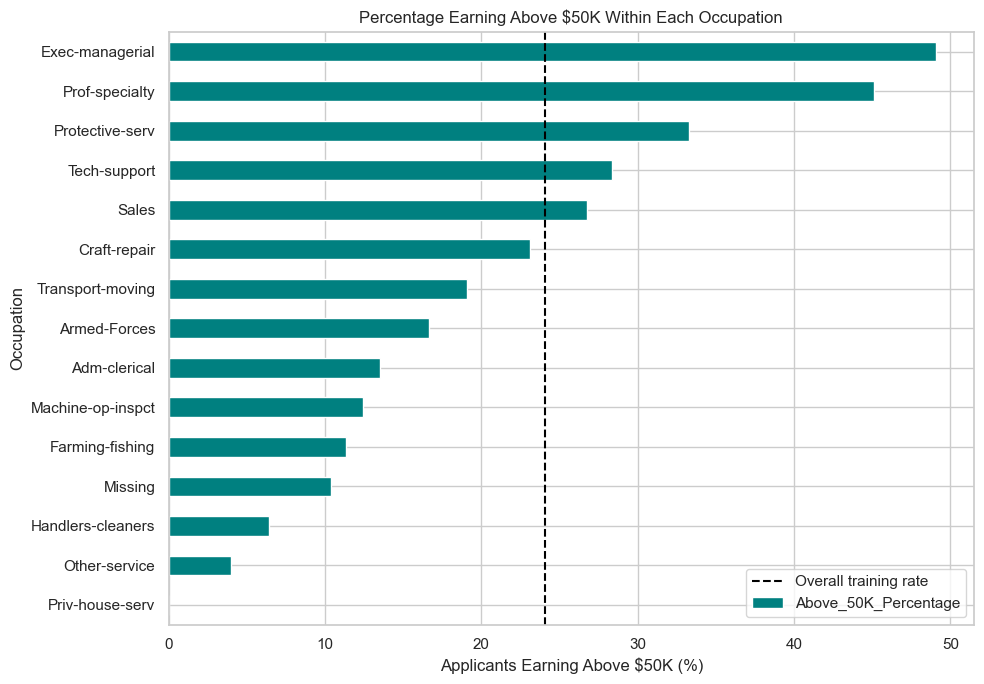

In [16]:
occupation_summary = (
    eda_df.groupby(eda_df["occupation"].fillna("Missing"))["income"]
    .agg(["size", "mean"])
)

occupation_summary.columns = ["Applicants", "Above_50K_Percentage"]
occupation_summary["Above_50K_Percentage"] *= 100

occupation_summary = occupation_summary.sort_values(
    "Above_50K_Percentage"
)

display(occupation_summary.round(2))

occupation_summary["Above_50K_Percentage"].plot.barh(
    figsize=(10, 7),
    color="teal"
)

plt.axvline(
    eda_df["income"].mean() * 100,
    color="black",
    linestyle="--",
    label="Overall training rate"
)

plt.title("Percentage Earning Above $50K Within Each Occupation")
plt.xlabel("Applicants Earning Above $50K (%)")
plt.ylabel("Occupation")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
categorical_columns = eda_df.select_dtypes(include="object").columns

categorical_summary = pd.DataFrame({
    "Unique_Categories": eda_df[categorical_columns].nunique(),
    "Missing_Count": eda_df[categorical_columns].isna().sum(),
    "Missing_Percentage": (
        eda_df[categorical_columns].isna().mean() * 100
    ).round(2)
})

display(categorical_summary)

,Unique_Categories,Missing_Count,Missing_Percentage
workclass,8,1305,5.73
education,16,0,0.00
marital.status,7,0,0.00
occupation,14,1310,5.75
relationship,6,0,0.00
race,5,0,0.00
sex,2,0,0.00
native.country,40,406,1.78
